# Unión de las 4 bases geoespaciales — Malla Vial, Puentes, Malla Peatonal y Semáforos

Este cuaderno consolida las **4 capas base** del proyecto, ya exploradas por separado en:

- `EDA_Malla_Vial_Puentes_zona_urbana.ipynb` → Malla Vial Integral (líneas) y Puentes (polígonos)
- `EDA_Malla_peatonal_semaforos.ipynb` → Malla Peatonal (líneas) y Semáforos (puntos)

**Enfoque de unión elegido: unión espacial por proximidad (`sjoin_nearest`).**

Como las 4 capas tienen geometrías y esquemas de columnas distintos (líneas, polígonos, puntos), no tiene sentido un `concat` fila a fila. En su lugar:

1. Se toma la **Malla Vial Integral** como capa base (esqueleto de la red).
2. **Puentes**, **Semáforos** y **Malla Peatonal** se relacionan cada uno con el segmento vial **más cercano**, agregando el identificador del segmento vial y la distancia (en metros) al resultado.
3. Se exporta un **GeoPackage único** con las 4 capas ya enriquecidas y en el mismo CRS, listo para análisis conjunto o cruces posteriores (ej. accidentalidad, semaforización por tipo de vía, etc.).

> **Nota:** este cuaderno asume la misma estructura de carpetas usada en los EDA originales (`Data/raw/...` para peatonal y semáforos, y los archivos de malla vial/puentes en el directorio de trabajo). Ajusta las rutas en la celda de carga si tu estructura es distinta.

## 1. Librerías

In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
plt.rcParams['figure.figsize'] = (9, 6)

## 2. Carga de las 4 capas

Mismas rutas usadas en los EDA originales. Ajusta si tu estructura de carpetas es distinta.

In [2]:
# Malla Vial Integral y Puentes (EDA_Malla_Vial_Puentes_zona_urbana.ipynb)
malla = gpd.read_file("./Malla_Vial_Integral_Bogota_D_C (3).geojson")
puentes = gpd.read_file("./Puente.gpkg")

# Malla Peatonal y Semáforos (EDA_Malla_peatonal_semaforos.ipynb)
peatonal = gpd.read_file("Data/raw/red_peatonal_conexion (1).gpkg")
semaforos = gpd.read_file("Data/raw/semaforos_bogota.geojson")

print("Malla vial :", malla.shape, "| CRS:", malla.crs)
print("Puentes    :", puentes.shape, "| CRS:", puentes.crs)
print("Peatonal   :", peatonal.shape, "| CRS:", peatonal.crs)
print("Semáforos  :", semaforos.shape, "| CRS:", semaforos.crs)

Malla vial : (136957, 43) | CRS: EPSG:4326
Puentes    : (1212, 6) | CRS: EPSG:4686
Peatonal   : (46065, 17) | CRS: PROJCS["PCS_CarMAGBOG",GEOGCS["GCS_CarMAGBOG",DATUM["CGS_CarMAGBOG",SPHEROID["GRS80 Mod",6380687,298.257222101]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",4.680486111],PARAMETER["central_meridian",-74.14659167],PARAMETER["scale_factor",1],PARAMETER["false_easting",92334.879],PARAMETER["false_northing",109320.965],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Semáforos  : (1745, 25) | CRS: EPSG:4326


## 3. Estandarización de CRS

Las 4 capas se llevan a `EPSG:3116` (MAGNA-SIRGAS / Bogotá, proyectado, metros), el mismo CRS usado en ambos EDA. Esto es indispensable para que `sjoin_nearest` calcule distancias reales en metros.

In [3]:
CRS_DESTINO = 3116

malla = malla.to_crs(CRS_DESTINO)
puentes = puentes.to_crs(CRS_DESTINO)
peatonal = peatonal.to_crs(CRS_DESTINO)
semaforos = semaforos.to_crs(CRS_DESTINO)

for nombre, capa in [('malla', malla), ('puentes', puentes), ('peatonal', peatonal), ('semaforos', semaforos)]:
    print(f"{nombre:10s} -> CRS: {capa.crs}, geom: {capa.geom_type.unique()}")

malla      -> CRS: EPSG:3116, geom: ['LineString' 'MultiLineString' None]
puentes    -> CRS: EPSG:3116, geom: ['MultiPolygon']
peatonal   -> CRS: EPSG:3116, geom: ['MultiLineString']
semaforos  -> CRS: EPSG:3116, geom: ['Point']


## 4. Limpieza mínima previa a la unión

Se replican las decisiones de limpieza ya hechas en los EDA originales: eliminar geometrías nulas/inválidas de la malla vial, y quedarnos con las columnas relevantes de cada capa (basado en lo detectado en cada EDA).

In [4]:
# --- Malla vial: eliminar geometrías nulas ---
malla = malla[~malla.geometry.isna()].copy()
malla['longitud_m'] = malla.geometry.length

# Identificador único de segmento vial para la unión
id_col_malla = 'MVICODIGO' if 'MVICODIGO' in malla.columns else 'OBJECTID'
malla = malla.rename(columns={id_col_malla: 'vial_id'})

cols_malla = [c for c in ['vial_id', 'MVITIPO', 'MVISVIA', 'MVIEVIA', 'PREFIJO', 'MVITSUP', 'longitud_m', 'geometry'] if c in malla.columns]
malla_base = malla[cols_malla].copy()
print(malla_base.shape)
malla_base.head()

(136956, 8)


,vial_id,MVITIPO,MVISVIA,MVIEVIA,PREFIJO,MVITSUP,longitud_m,geometry
0,96282,KR,SD,M,SE,2,35.425891,"LINESTRING (997702.139 993255.081, 997674.788 ..."
1,62558,CL,B,M,S,6,25.743885,"LINESTRING (989012.577 1005585.74, 988998.75 1..."
2,33964,TV,B,M,,1,95.373241,"LINESTRING (1006180.996 1007998.51, 1006201.46..."
3,29147,CL,B,R,,6,117.076476,"LINESTRING (1005380.357 1018221.924, 1005369.9..."
4,133742,KR,B,M,,12,59.005266,"LINESTRING (992300.356 1005275.881, 992343.913..."


In [5]:
# --- Puentes: eliminar geometrías nulas/inválidas y calcular métricas ---
puentes = puentes[~puentes.geometry.isna()].copy()
puentes['perimetro_m'] = puentes.geometry.length
puentes['area_m2'] = puentes.geometry.area
print(puentes.shape)
puentes.head()

(1212, 8)


,PueCodigo,PueTipo,PueUbicaci,SHAPE_Length,SHAPE_Area,geometry,perimetro_m,area_m2
0,22156629,1,Avenida José Celestino Mutis por Avenida del C...,0.000971,4.708416e-08,"MULTIPOLYGON (((998280.597 1007762.268, 998280...",107.539799,577.692282
1,24119247,1,Avenida José Celestino Mutis por Avenida del C...,0.000970,4.394591e-08,"MULTIPOLYGON (((998235.48 1007693.897, 998233....",107.458677,539.188631
2,24119314,1,Avenida Jorge Uribe Botero por Avenida de los ...,0.001157,2.512141e-08,"MULTIPOLYGON (((1004041.067 1014743.721, 10040...",128.025452,308.196652
3,22158560,1,Avenida Paseo Del Country por Avenida Carlos L...,0.000605,1.620756e-08,"MULTIPOLYGON (((1003223.483 1009834.876, 10032...",67.044714,198.851261
4,22158594,1,Avenida Laureano Gómez por Avenida Carlos Ller...,0.000729,2.609475e-08,"MULTIPOLYGON (((1003191.943 1009797.853, 10032...",80.817955,320.157757


In [6]:
# --- Malla peatonal: mismas columnas seleccionadas en el EDA original ---
cols_peatonal = [c for c in ['OBJECTID', 'CODIGO_ID', 'NOMBRE', 'Shape_Length', 'geometry'] if c in peatonal.columns]
peatonal = peatonal[cols_peatonal].copy()
peatonal = peatonal[~peatonal.geometry.isna()].copy()
print(peatonal.shape)
peatonal.head()

(46065, 5)


,OBJECTID,CODIGO_ID,NOMBRE,Shape_Length,geometry
0,1,1,SIN_NMG,81.897416,"MULTILINESTRING ((997041.195 1002737.492, 9970..."
1,2,2,SIN_NMG,106.148218,"MULTILINESTRING ((999079.192 1000536.956, 9990..."
2,3,3,AVENIDA CIUDAD MONTES,64.803378,"MULTILINESTRING ((997805.024 1000541.845, 9977..."
3,4,4,SIN_NMG,47.252468,"MULTILINESTRING ((992561.034 1001290.312, 9925..."
4,5,5,AVENIDA CIUDAD DE VILLAVICENCIO,39.255541,"MULTILINESTRING ((994278.782 997168.094, 99427..."


In [7]:
# --- Semáforos: eliminar geometrías nulas ---
semaforos = semaforos[~semaforos.geometry.isna()].copy()
print(semaforos.shape)
semaforos.head()

(1745, 25)


,OBJECTID,ID,EXTERNO,DIRECCION,LOCALIDAD,EQUIPO,NUMEROINTERSECCIONES_POREQUIPO,UBICACIONEQUIPO,FECHAINSTALACION,OPERACIONACTUAL,FUNCIONAMIENTO,IMPLEMENTACION,TIPOINTERSECCION,GRUPOSENALES,TOTALGRUPOSENALES,NUMEROFASES,GRUPOSVEHICULARES,GRUPOS_BRT,GRUPOSPEATONALES,GRUPOSSONOROS,GRUPOSCICLISTAS,CANTIDADCONTADORES,FUNCIONDETECTORES,ZONAAUTOMATICA,geometry
0,1,1172,1001,AK 11 X CL 66,CHAPINERO,ACTROS,SENCILLA,SI,1998-02-08 00:00:00+00:00,NORMAL,CA-TA,DEFINITIVA,"VEHICULAR, PEATONAL",4,4,2,"1,3",N/A,"21,23",N/A,NO,0,"Conteo, Brechas",1910,POINT Z (1001745.665 1006169.819 0)
1,2,203,1002,AK 11 X CL 69,CHAPINERO,NO,DOBLE,NO,1994-03-10 00:00:00+00:00,NORMAL,CA-TA,DEFINITIVA,"VEHICULAR, PEATONAL",6,10,3,"1,3",N/A,"21,23,31,33",N/A,NO,0,"Conteo, Brechas, Fases por demanda",1910,POINT Z (1001852.065 1006399.768 0)
2,3,213,1002,AK 11 X CL 67,CHAPINERO,ACTROS,DOBLE,SI,1994-03-10 00:00:00+00:00,NORMAL,CA-TA,DEFINITIVA,"VEHICULAR, PEATONAL",4,10,2,"4,11",N/A,"24,211",N/A,NO,0,"Conteo, Brechas, Fases por demanda",1910,POINT Z (1001784.115 1006253.269 0)
3,4,73,1003,AK 7 X AC 85,CHAPINERO,C900,SENCILLA,SI,1997-12-23 00:00:00+00:00,NORMAL,CA-TA,DEFINITIVA,"VEHICULAR, PEATONAL",8,8,3,"1,2,2A,3,6",N/A,"21,23,32",N/A,NO,0,"Conteo, Brechas, Fases por demanda",1901,POINT Z (1003406.253 1007626.821 0)
4,5,75,1004,AK 1 X CL 85,CHAPINERO,NO,DOBLE,NO,1997-09-04 00:00:00+00:00,NORMAL,CA-TA,DEFINITIVA,EXCLUSIVA VEHICULAR,3,13,2,"2,3",1B,N/A,N/A,NO,0,"Conteo, Brechas, Cola",1901,POINT Z (1003437.854 1007557.407 0)


## 5. Unión espacial por proximidad

Se usa `gpd.sjoin_nearest`, que para cada geometría de la capa izquierda encuentra la geometría más cercana de la capa derecha (`malla_base`) y añade su distancia real en metros (`dist_m`).

Se define una función auxiliar reutilizable para las 3 uniones (puentes, semáforos, peatonal → malla vial).

In [8]:
def unir_a_malla_mas_cercana(capa, malla_base, sufijo, max_distancia=None):
    """
    Une `capa` con el segmento vial más cercano de `malla_base`.
    Agrega columnas 'vial_id', 'MVITIPO', 'MVISVIA' (si existen) y 'dist_m'.
    """
    cols_vial = [c for c in ['vial_id', 'MVITIPO', 'MVISVIA'] if c in malla_base.columns] + ['geometry']
    resultado = gpd.sjoin_nearest(
        capa,
        malla_base[cols_vial],
        how='left',
        distance_col='dist_m',
        lsuffix='',
        rsuffix='vial'
    )
    resultado = resultado.drop(columns=[c for c in resultado.columns if c == 'index_vial'], errors='ignore')
    if max_distancia is not None:
        n_lejos = (resultado['dist_m'] > max_distancia).sum()
        print(f"[{sufijo}] {n_lejos} de {len(resultado)} registros a más de {max_distancia} m del segmento vial más cercano")
    return resultado

In [9]:
UMBRAL_M = 100  # metros; solo para reportar, no se filtra nada por defecto

puentes_unido = unir_a_malla_mas_cercana(puentes, malla_base, 'puentes', UMBRAL_M)
semaforos_unido = unir_a_malla_mas_cercana(semaforos, malla_base, 'semaforos', UMBRAL_M)
peatonal_unido = unir_a_malla_mas_cercana(peatonal, malla_base, 'peatonal', UMBRAL_M)

print("\nPuentes unidos   :", puentes_unido.shape)
print("Semáforos unidos :", semaforos_unido.shape)
print("Peatonal unida   :", peatonal_unido.shape)

[puentes] 32 de 4300 registros a más de 100 m del segmento vial más cercano
[semaforos] 1 de 1755 registros a más de 100 m del segmento vial más cercano
[peatonal] 6 de 55389 registros a más de 100 m del segmento vial más cercano

Puentes unidos   : (4300, 12)
Semáforos unidos : (1755, 29)
Peatonal unida   : (55389, 9)


### 5.1 Distribución de distancias al segmento vial más cercano

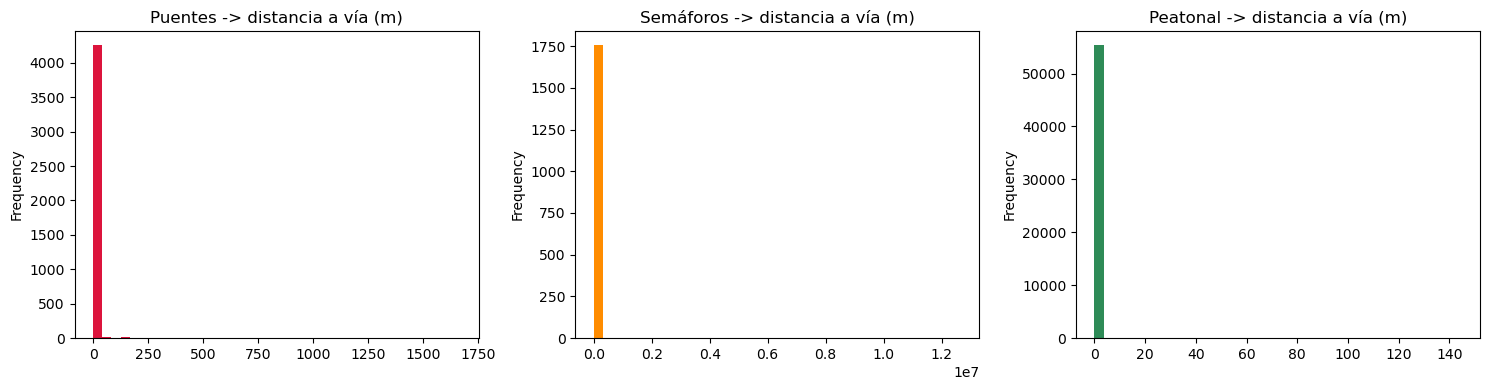

Puentes -> dist_m describe:
count    4300.000000
mean        4.676823
std        62.176871
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      1670.483220
Name: dist_m, dtype: float64

Semáforos -> dist_m describe:
count    1.755000e+03
mean     7.221893e+03
std      3.024331e+05
min      3.992588e-10
25%      5.952459e-01
50%      1.505424e+00
75%      3.428601e+00
max      1.266975e+07
Name: dist_m, dtype: float64

Peatonal -> dist_m describe:
count    55389.000000
mean         0.036604
std          1.348937
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000170
max        144.801950
Name: dist_m, dtype: float64



In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

puentes_unido['dist_m'].plot(kind='hist', bins=40, ax=axes[0], color='crimson')
axes[0].set_title('Puentes -> distancia a vía (m)')

semaforos_unido['dist_m'].plot(kind='hist', bins=40, ax=axes[1], color='darkorange')
axes[1].set_title('Semáforos -> distancia a vía (m)')

peatonal_unido['dist_m'].plot(kind='hist', bins=40, ax=axes[2], color='seagreen')
axes[2].set_title('Peatonal -> distancia a vía (m)')

plt.tight_layout()
plt.show()

for nombre, capa in [('Puentes', puentes_unido), ('Semáforos', semaforos_unido), ('Peatonal', peatonal_unido)]:
    print(nombre, '-> dist_m describe:')
    print(capa['dist_m'].describe())
    print()

## 6. Vista conjunta de las 4 capas ya unidas

Recorte a la zona urbana (mismos límites usados en los EDA originales).

C:\Users\Brayan\AppData\Local\Temp\ipykernel_10008\4044024555.py:12: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc='lower right')


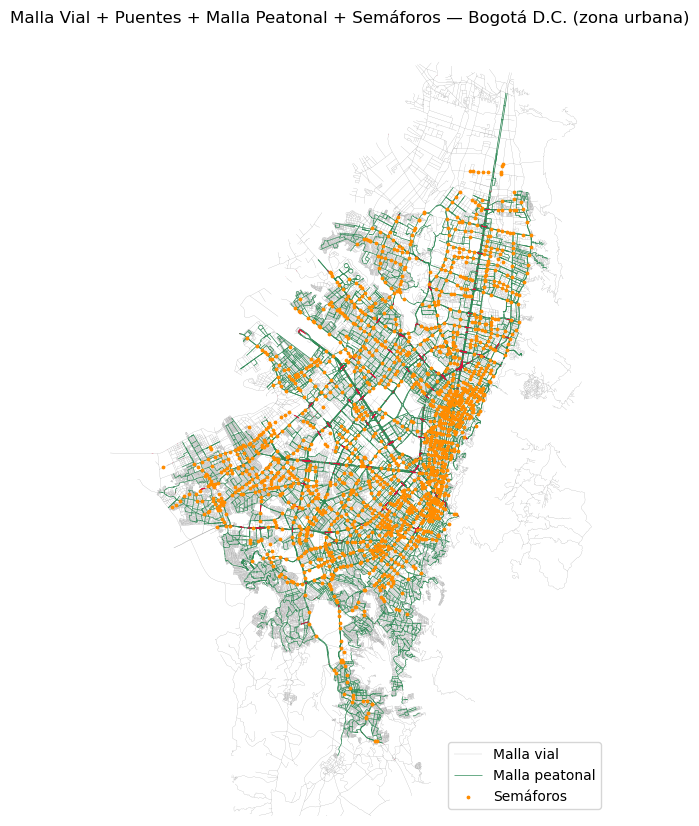

In [11]:
fig, ax = plt.subplots(figsize=(10, 10))

malla_base.plot(ax=ax, linewidth=0.12, color='gray', zorder=1, label='Malla vial')
peatonal_unido.plot(ax=ax, linewidth=0.5, color='seagreen', zorder=2, label='Malla peatonal')
puentes_unido.plot(ax=ax, color='crimson', markersize=4, zorder=3, label='Puentes')
semaforos_unido.plot(ax=ax, color='darkorange', markersize=3, zorder=4, label='Semáforos')

ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Malla Vial + Puentes + Malla Peatonal + Semáforos — Bogotá D.C. (zona urbana)')
ax.set_axis_off()
ax.legend(loc='lower right')
plt.show()

## 7. Exportar el resultado consolidado

Se guarda un único **GeoPackage** con 4 capas (una por dataset), cada una ya en `EPSG:3116` y con la información de unión (`vial_id`, `dist_m`) donde aplica. Esto facilita abrir todo en QGIS o volver a cargarlo en pandas/geopandas por capa.

In [12]:
import os
os.makedirs('Data/processed', exist_ok=True)

salida = 'Data/processed/malla_urbana_unificada.gpkg'

malla_base.to_file(salida, layer='malla_vial', driver='GPKG')
puentes_unido.to_file(salida, layer='puentes', driver='GPKG')
semaforos_unido.to_file(salida, layer='semaforos', driver='GPKG')
peatonal_unido.to_file(salida, layer='peatonal', driver='GPKG')

print('Archivo generado:', salida)
print('Capas:', ['malla_vial', 'puentes', 'semaforos', 'peatonal'])

Archivo generado: Data/processed/malla_urbana_unificada.gpkg
Capas: ['malla_vial', 'puentes', 'semaforos', 'peatonal']


## 8. Resumen

- Las 4 capas se estandarizaron a un único CRS (`EPSG:3116`), condición necesaria para cualquier unión espacial.
- **Puentes**, **Semáforos** y **Malla Peatonal** se unieron a la **Malla Vial Integral** por proximidad (`sjoin_nearest`), añadiendo el `vial_id` del segmento más cercano y la distancia real en metros (`dist_m`).
- Se reportó cuántos registros de cada capa quedan a más de 100 m del segmento vial más cercano — útil para detectar posibles errores de digitalización o zonas peatonales/puentes no directamente asociadas a la malla vial modelada.
- El resultado se consolidó en un único GeoPackage (`Data/processed/malla_urbana_unificada.gpkg`) con 4 capas, listo para análisis conjunto o para cargar en un SIG.

**Siguientes pasos sugeridos:** cruzar `vial_id` entre capas para, por ejemplo, contar semáforos por tipo de vía (`MVITIPO`), o analizar la cobertura de malla peatonal por segmento vial.